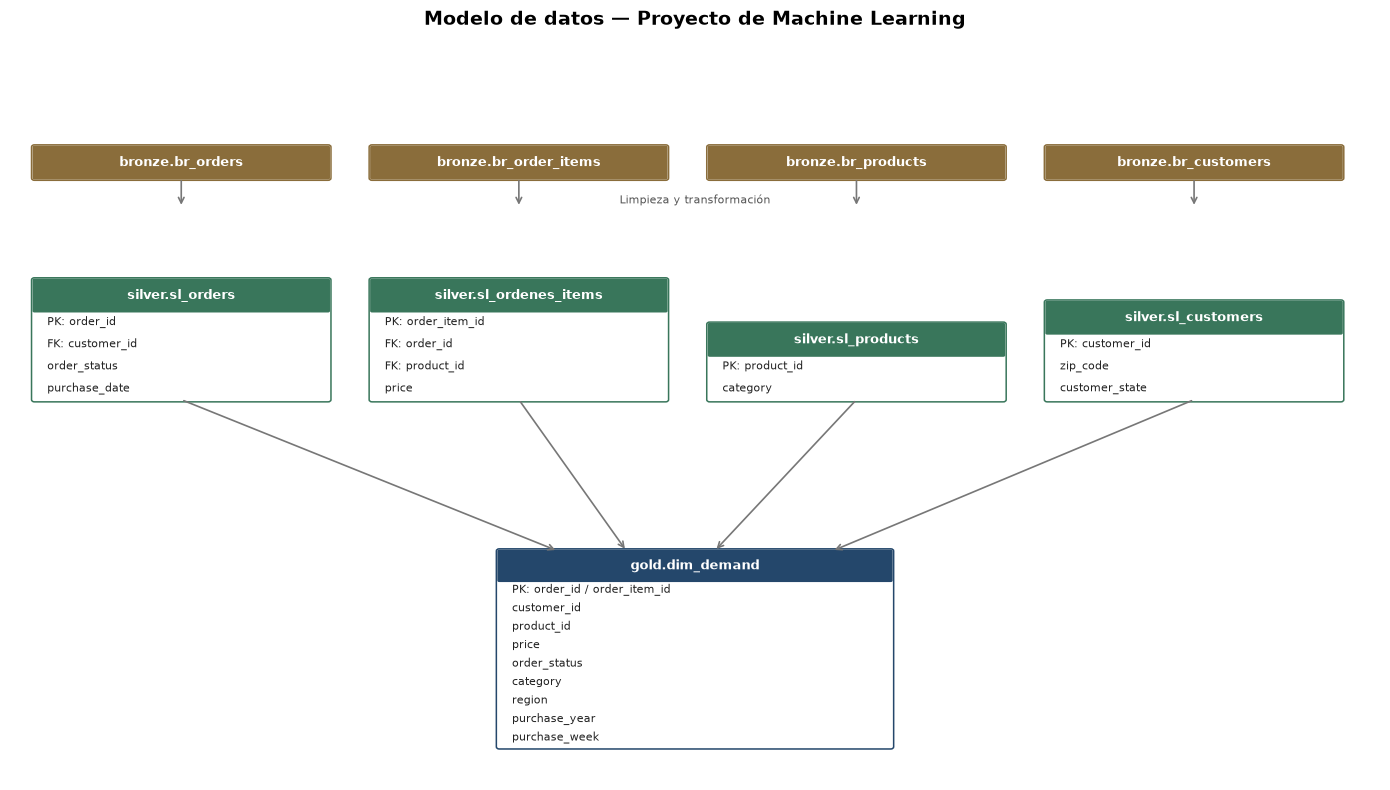

In [10]:

import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch

# --------------------------------------------------
# CONFIGURACIÓN GENERAL
# --------------------------------------------------

fig, ax = plt.subplots(figsize=(14, 8))

ax.set_xlim(0, 14)
ax.set_ylim(0, 10)
ax.axis("off")


# --------------------------------------------------
# FUNCIÓN PARA DIBUJAR TABLAS
# --------------------------------------------------

def draw_table(
    x, y, width, title, columns, color,
    row_height=0.30, header_height=0.42
):
    height = header_height + len(columns) * row_height

    # Cuerpo de la tabla
    box = FancyBboxPatch(
        (x, y), width, height,
        boxstyle="round,pad=0.03",
        linewidth=1.1,
        edgecolor=color,
        facecolor="white"
    )
    ax.add_patch(box)

    # Encabezado
    header = FancyBboxPatch(
        (x, y + height - header_height),
        width, header_height,
        boxstyle="round,pad=0.02",
        linewidth=0,
        facecolor=color
    )
    ax.add_patch(header)

    ax.text(
        x + width / 2,
        y + height - header_height / 2,
        title,
        ha="center",
        va="center",
        color="white",
        fontsize=9,
        fontweight="bold"
    )

    # Una columna por fila
    for i, column in enumerate(columns):
        text_y = (
            y + height - header_height
            - (i + 0.5) * row_height
        )

        ax.text(
            x + 0.13,
            text_y,
            column,
            ha="left",
            va="center",
            fontsize=8,
            color="#222222"
        )

    return height


# --------------------------------------------------
# FUNCIÓN PARA DIBUJAR FLECHAS
# --------------------------------------------------

def connect(x1, y1, x2, y2):
    ax.annotate(
        "",
        xy=(x2, y2),
        xytext=(x1, y1),
        arrowprops=dict(
            arrowstyle="->",
            color="#777777",
            linewidth=1.2
        )
    )


# --------------------------------------------------
# CAPA BRONZE
# --------------------------------------------------

bronze_color = "#8A6D3B"

bronze_tables = [
    (0.25, "bronze.br_orders"),
    (3.70, "bronze.br_order_items"),
    (7.15, "bronze.br_products"),
    (10.60, "bronze.br_customers")
]

bronze_width = 3.0
bronze_y = 8.15

for x, title in bronze_tables:
    draw_table(
        x, bronze_y, bronze_width,
        title,
        [],  # Columnas omitidas en esta vista conceptual
        bronze_color,
        row_height=0.25
    )


# --------------------------------------------------
# CAPA SILVER
# --------------------------------------------------

silver_color = "#39765B"
silver_y = 5.15
silver_width = 3.0

silver_tables = [
    (
        0.25,
        "silver.sl_orders",
        [
            "PK: order_id",
            "FK: customer_id",
            "order_status",
            "purchase_date"
        ]
    ),
    (
        3.70,
        "silver.sl_ordenes_items",
        [
            "PK: order_item_id",
            "FK: order_id",
            "FK: product_id",
            "price"
        ]
    ),
    (
        7.15,
        "silver.sl_products",
        [
            "PK: product_id",
            "category"
        ]
    ),
    (
        10.60,
        "silver.sl_customers",
        [
            "PK: customer_id",
            "zip_code",
            "customer_state"
        ]
    )
]

for x, title, columns in silver_tables:
    draw_table(
        x, silver_y, silver_width,
        title, columns, silver_color
    )


# --------------------------------------------------
# FLUJO BRONZE -> SILVER
# --------------------------------------------------

bronze_centers = [1.75, 5.20, 8.65, 12.10]

for center_x in bronze_centers:
    connect(
        center_x, bronze_y,
        center_x, 7.75
    )

ax.text(
    7, 7.85,
    "Limpieza y transformación",
    ha="center",
    va="center",
    fontsize=8,
    color="#555555",
    bbox=dict(facecolor="white", edgecolor="none", pad=2)
)


# --------------------------------------------------
# CAPA GOLD
# --------------------------------------------------

gold_color = "#24476B"

gold_x = 5.0
gold_y = 0.45
gold_width = 4.0

gold_columns = [
    "PK: order_id / order_item_id",
    "customer_id",
    "product_id",
    "price",
    "order_status",
    "category",
    "region",
    "purchase_year",
    "purchase_week"
]

gold_height = draw_table(
    gold_x, gold_y, gold_width,
    "gold.dim_demand",
    gold_columns,
    gold_color,
    row_height=0.25,
    header_height=0.40
)


# --------------------------------------------------
# FLUJO SILVER -> GOLD
# --------------------------------------------------

silver_bottom = silver_y

# Puntos de salida debajo de cada tabla Silver
silver_centers = [1.75, 5.20, 8.65, 12.10]
gold_targets = [5.6, 6.3, 7.2, 8.4]

for source_x, target_x in zip(
    silver_centers, gold_targets
):
    connect(
        source_x, silver_bottom,
        target_x, gold_y + gold_height
    )


# --------------------------------------------------
# TÍTULO
# --------------------------------------------------

ax.set_title(
    "Modelo de datos — Proyecto de Machine Learning",
    fontsize=14,
    fontweight="bold",
    pad=12
)

plt.tight_layout()
plt.show()


## Para crear la tabla gold, se utilizaron las tablas orders, ordenes_items, products y customers:


order_id         > order_id junto con order_item_id crea una FK compuesta. Se necesita una clave compuesta para poder poblar la capa ya que hay compras de varios productos con un mismo order_id, por tanto se debe diferenciar cada compra con un PK distinto.
customer_id      > customer_id da acceso a la columna customer_state, que se utilizó para separar las compras por las 5 regiones geográficas en las que se divide Brasil para efectos estadísticos y económicos.
product_id       > product_id da acceso a la columna category con la que podemos separar por categoría del producto las compras realizadas.
order_item_id    > order_item_id da acceso a la columna price para obtener la demanda en términos de dinero.
price            > el monto total de la compra.
order_status     > nos indica el estado de la compra: cancelado, entregado, no entregado.
purchase_week    > a través de order_id obtenemos la fecha en la que la compra fue realizada, segmentado por semana.
purchase_year    > fecha en que se realizó la compra, segmentado por año. Como el dataset abarca dos años y hemos decidido crear la predicción por semana necesitamos separar, por ejemplo, la semana 20 del año 2016 con la semana 20 del año 2018.
category         > el tipo de producto que se vendio en la orden.
region           > la región en la que vive el consumidor que realizó la compra



## Para poblar la tabla, hemos utilizado el siguiente script:

# Insert usando los datos de la tabla gold
INSERT INTO gold.dim_demand 
(
    order_id,
    customer_id,
    product_id,
    order_item_id,
    price,
    order_status,
    category,
    purchase_year,
    purchase_week,
    region


# En el select ejecutamos los joins de todas las tablas. 
# Para obtener el purchase_year y purchase_week hemos transformado purchase_date de la tabla ordenes.
# Creamos un case para separar todos los 27 estados de Brasil en las 5 regiones: norte, noreste, sudeste, sur y centro-oeste.
# Agregamos una regla where order_status = delivered porque solo queremos tener datos de compras que fueron completadas y entregadas al consumidor final, si tomar en cuenta compras canceladas.

)
SELECT
    o.order_id,
    o.customer_id,
    oi.product_id,
    oi.order_item_id,
    oi.price,
    o.order_status,
    p.category,
    YEAR(o.purchase_date) AS purchase_year,           
    DATEPART(ISO_WEEK, o.purchase_date) AS purchase_week,

    CASE
        WHEN c.customer_state IN ('AC', 'AP', 'AM', 'PA', 'RO', 'RR', 'TO')
            THEN 'Norte'

        WHEN c.customer_state IN ('AL', 'BA', 'CE', 'MA', 'PB', 'PE', 'PI', 'RN', 'SE')
            THEN 'Nordeste'

        WHEN c.customer_state IN ('DF', 'GO', 'MS', 'MT')
            THEN 'Centro-Oeste'

        WHEN c.customer_state IN ('ES', 'MG', 'RJ', 'SP')
            THEN 'Sudeste'

        WHEN c.customer_state IN ('PR', 'RS', 'SC')
            THEN 'Sul'

        ELSE 'Desconocida'
    END AS region

FROM silver.sl_orders AS o

INNER JOIN silver.sl_ordenes_items AS oi
    ON o.order_id = oi.order_id

INNER JOIN silver.sl_products AS p
    ON oi.product_id = p.product_id

INNER JOIN silver.sl_customers AS c
    ON o.customer_id = c.customer_id

WHERE o.order_status = 'delivered';